In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/donorpulse_synthetic_dataset.csv")
df["interaction_date"] = pd.to_datetime(df["interaction_date"])
df["followup_due_date"] = pd.to_datetime(df["followup_due_date"])
df["donation_date"] = pd.to_datetime(df["donation_date"])

df.head()

,interaction_id,donor_id,age_group,city_tier,previous_donor,previous_donations,total_previous_amount,campaign_id,campaign_name,campaign_type,...,contact_status,disposition,followup_required,followup_due_date,followup_completed,days_since_last_contact,duplicate_contact,converted,donation_amount,donation_date
0,I000001,D00636,36-45,Tier 1,1,4,9669.03,C001,Education Access,Education,...,No Answer,No Answer,0,NaT,0,31,0,0,0.00,NaT
1,I000002,D00570,36-45,Tier 3,1,5,30703.34,C001,Education Access,Education,...,No Answer,No Answer,0,NaT,0,59,0,0,0.00,NaT
2,I000003,D00466,26-35,Tier 2,0,0,0.00,C001,Education Access,Education,...,Connected,Interested,1,2026-06-12,1,63,0,0,0.00,NaT
3,I000004,D01815,46-60,Tier 2,0,0,0.00,C003,Disaster Relief,Emergency,...,Busy,Busy,0,NaT,0,167,0,0,0.00,NaT
4,I000005,D00528,26-35,Tier 1,1,2,5280.71,C004,Women Skills,Livelihood,...,Connected,Call Back,1,2026-03-16,1,167,0,1,1258.66,2026-03-13


In [3]:
conversion_rate = df["converted"].mean() * 100

print("Conversion Rate:", round(conversion_rate, 2), "%")

Conversion Rate: 9.03 %


In [4]:
donations = df[df["donation_amount"] > 0]

print("Number of donations:", len(donations))
print("Average donation: ₹", round(donations["donation_amount"].mean(), 2))
print("Maximum donation: ₹", round(donations["donation_amount"].max(), 2))

Number of donations: 903
Average donation: ₹ 1499.07
Maximum donation: ₹ 10322.24


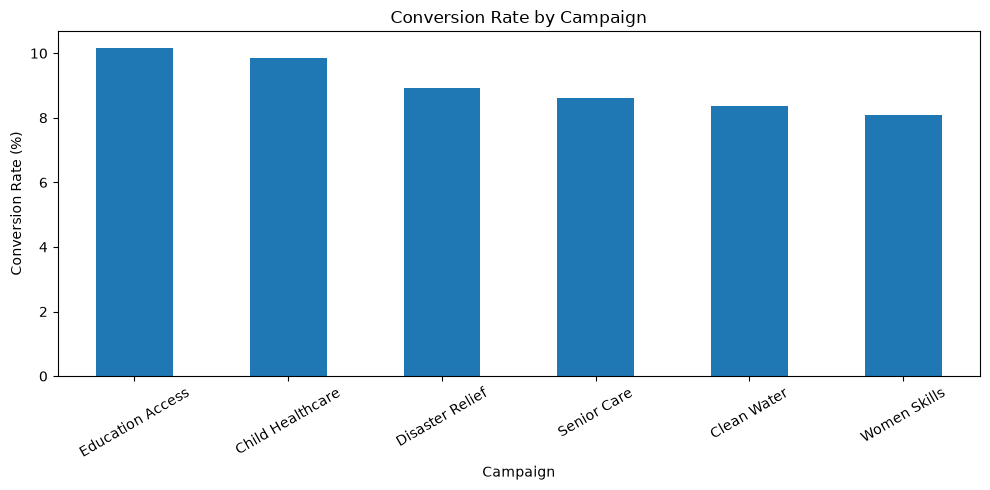

In [5]:
campaign_conversion = (
    df.groupby("campaign_name")["converted"]
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(10, 5))

campaign_conversion.plot(kind="bar")

plt.title("Conversion Rate by Campaign")
plt.xlabel("Campaign")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

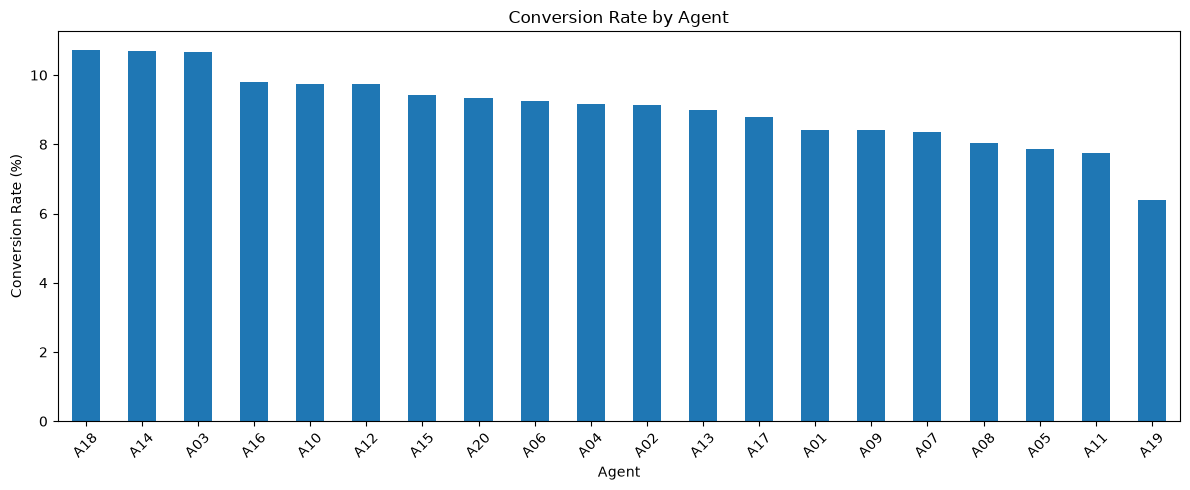

In [9]:
agent_conversion = (
    df.groupby("agent_id")["converted"]
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(12, 5))

agent_conversion.plot(kind="bar")

plt.title("Conversion Rate by Agent")
plt.xlabel("Agent")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()